In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from PortfolioOptimization import get_yearly_report

In [2]:
max_risk = 0.10

In [3]:
output_dir = './Output/Change in Max Risk'
os.makedirs(output_dir, exist_ok=True)
output_dir = f'{output_dir}/{max_risk:.2%}'
os.makedirs(output_dir, exist_ok=True)
os.makedirs(f'{output_dir}/Graphs', exist_ok=True)

In [4]:
from Portfolios.GSPCBuyAndHold import BuyAndHold
from Portfolios.EqualWeights import EqWeightPortfolio
from Portfolios.Markowitz import MarkowitzPortfolio
from Portfolios.MeanAbsDev import MeanAbsDevPortfolio
# from Portfolios.MedAbsDev import MedianAbsDevPortfolio

portfolios = {
    'S&P BnH': BuyAndHold,
    'Equal': EqWeightPortfolio,
    'Markowitz': MarkowitzPortfolio,
    'MAD': MeanAbsDevPortfolio,
    # 'MedAD': MedianAbsDevPortfolio,
}

reports = {}

In [5]:
for name, portfolio in portfolios.items():
    weights, stats = get_yearly_report(portfolio, max_risk)
    reports[name] = {
        'weights': weights,
        'stats': stats
    }
    stats_used = list(stats.columns)
    stats_used.remove('Year')

# Weight Analysis

In [6]:
weights_collector = None
for portfolio, report in reports.items():
    weights = report['weights'].copy()
    weights.columns = ['Year'] \
                        + [(portfolio, column)
                            for column in weights.columns
                            if column != 'Year']
    weights = weights.set_index('Year')

    weights.columns = pd.MultiIndex.from_tuples(weights.columns)
    
    if weights_collector is None:
        weights_collector = weights
    else:
        weights_collector = pd.merge(
                                weights_collector,
                                weights,
                                left_index=True,
                                right_index=True
                            )

weights_collector.to_excel(f'{output_dir}/Weights.xlsx')

# Statistic Analysis

In [7]:
# Combine Stats files
stats_collector = None
for portfolio, report in reports.items():
    stats = report['stats'].copy()
    stats.columns = ['Year'] \
                        + [(portfolio, column)
                            for column in stats.columns
                            if column != 'Year']
    stats = stats.set_index('Year')

    stats.columns = pd.MultiIndex.from_tuples(stats.columns)
    
    if stats_collector is None:
        stats_collector = stats
    else:
        stats_collector = pd.merge(
                            stats_collector, 
                            stats, 
                            left_index=True, 
                            right_index=True
                        )

stats_collector.to_excel(f'{output_dir}/Stats.xlsx')

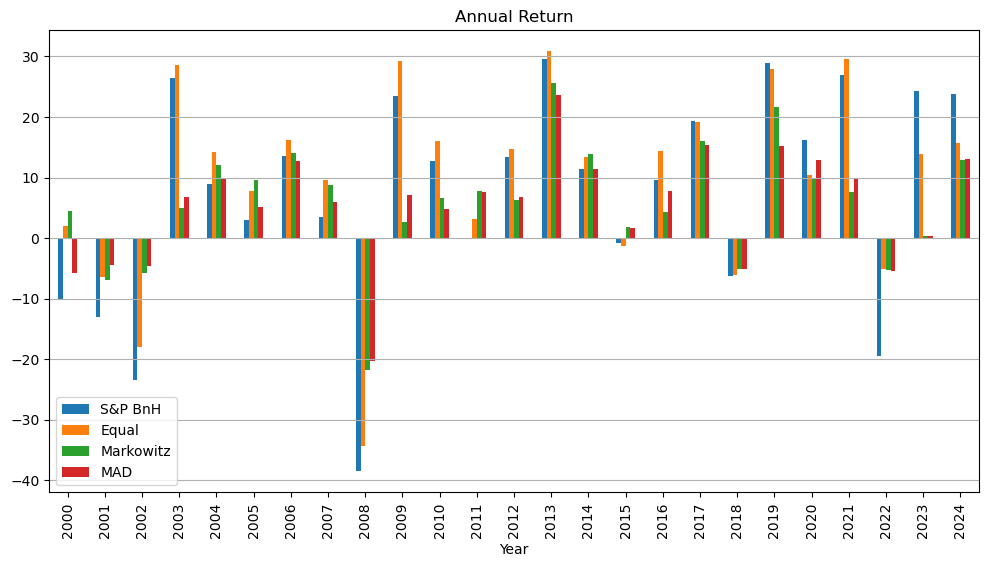

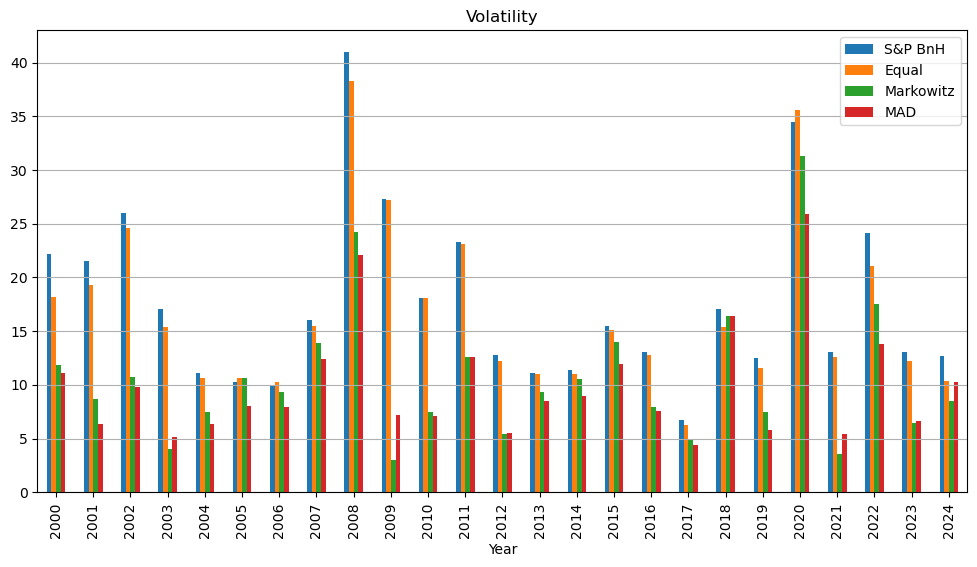

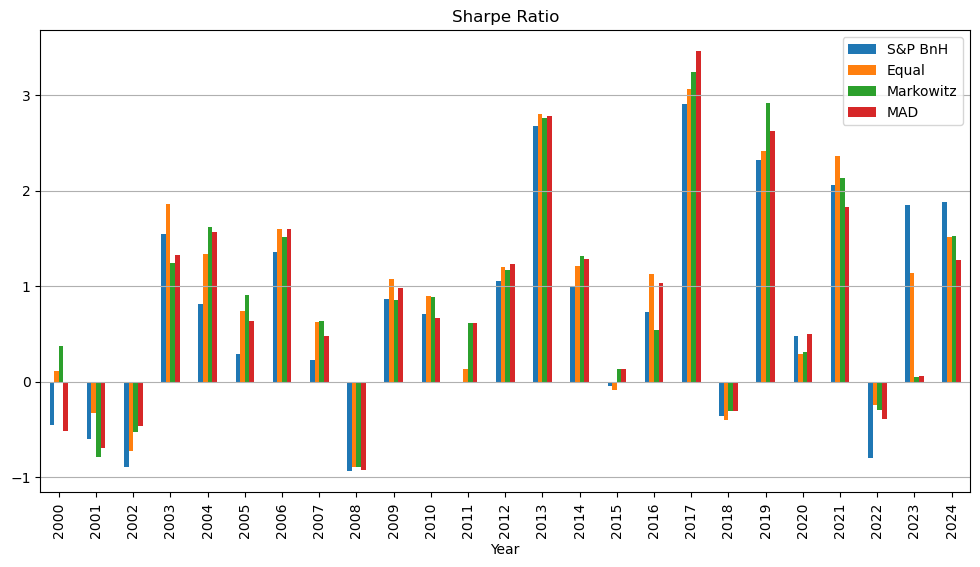

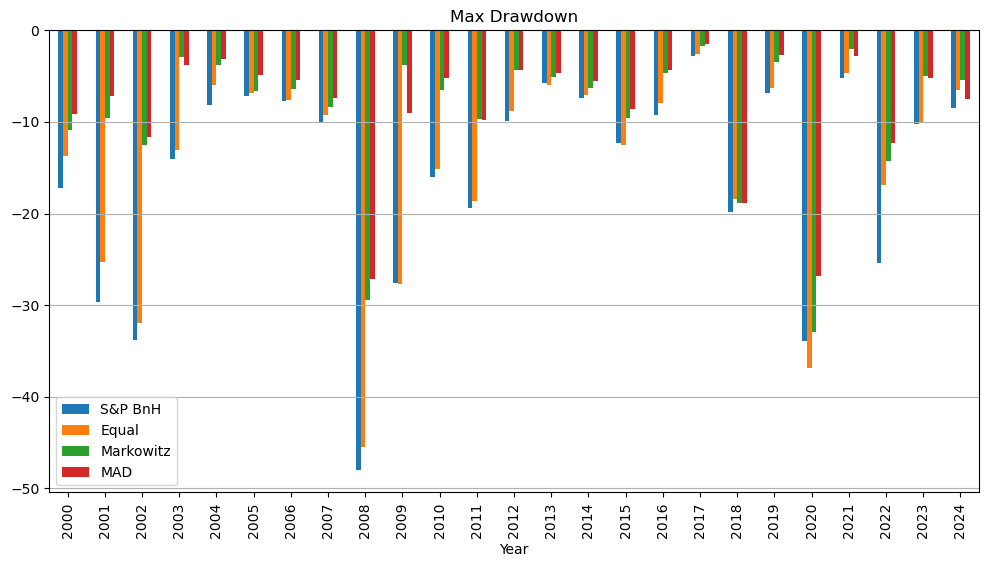

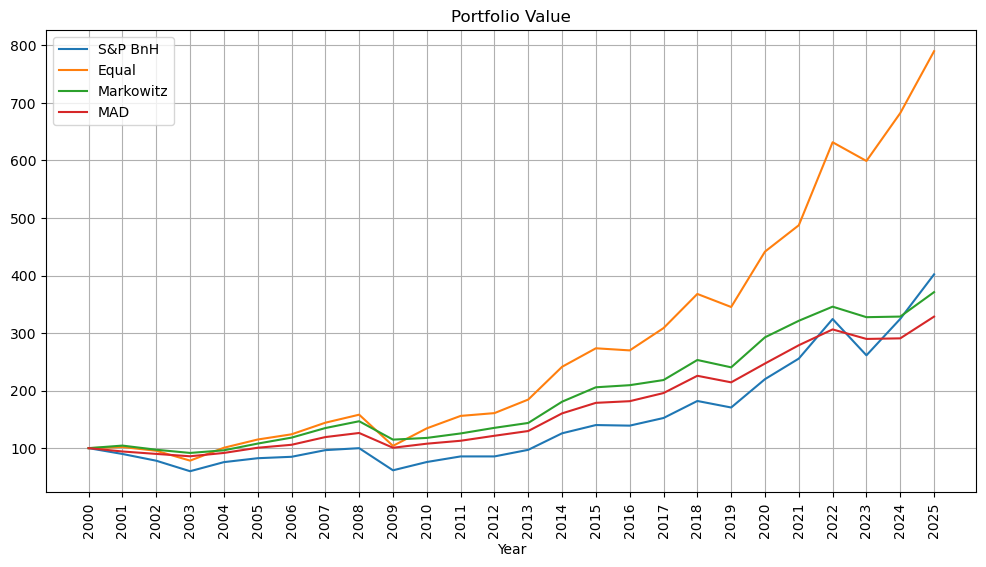

In [8]:
for stat in stats_used:
    stats = {}

    for portfolio in portfolios.keys():
        stats[portfolio] = stats_collector[portfolio][stat]
    
    stats = pd.DataFrame(stats)
    
    if stat == 'Portfolio Value':
        stats.index = stats.index + 1
        stats.loc[2000] = [100] * len(stats.keys())
        stats = stats.sort_index()
        stats.plot.line(figsize=(12, 6))
        plt.grid()
        plt.xticks(stats.index, rotation=90)
    else:
        stats.plot.bar(figsize=(12, 6))
        plt.grid(which='both', axis='y')
        
    plt.title(stat)
    plt.legend()
    plt.savefig(f'{output_dir}/Graphs/{stat}.png', bbox_inches='tight')
    plt.show()
    plt.close()

    del stats